# Deep Learning for Perception — Assignment 2, Section B


## 1. Setup and random seeds

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random

from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
SEEDS = [42, 123, 2026]

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

tf.config.experimental.enable_op_determinism()
set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Random seed:", SEED)

TensorFlow version: 2.21.0
Random seed: 42


## 2. CIFAR-10 loading and stratified data split

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = (
    keras.datasets.cifar10.load_data()
)

y_train_full = y_train_full.flatten()
y_test = y_test.flatten()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Training images:", x_train_full.shape)
print("Test images:", x_test.shape)
print("Number of classes:", len(class_names))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1729s 10us/step
Training images: (50000, 32, 32, 3)
Test images: (10000, 32, 32, 3)
Number of classes: 10


In [3]:
rng = np.random.default_rng(SEED)

train_indices = []
val_indices = []

for class_id in range(10):
    indices = np.where(y_train_full == class_id)[0]
    selected = rng.choice(indices, size=50, replace=False)
    selected = rng.permutation(selected)

    train_indices.extend(selected[:40])
    val_indices.extend(selected[40:])

train_indices = np.array(train_indices)
val_indices = np.array(val_indices)

x_train = x_train_full[train_indices].astype("float32") / 255.0
y_train = y_train_full[train_indices]

x_val = x_train_full[val_indices].astype("float32") / 255.0
y_val = y_train_full[val_indices]

print("Training:", x_train.shape)
print("Validation:", x_val.shape)

print("Training per class:", np.bincount(y_train))
print("Validation per class:", np.bincount(y_val))

assert x_train.shape[0] == 400
assert x_val.shape[0] == 100
assert len(set(train_indices) & set(val_indices)) == 0

Training: (400, 32, 32, 3)
Validation: (100, 32, 32, 3)
Training per class: [40 40 40 40 40 40 40 40 40 40]
Validation per class: [10 10 10 10 10 10 10 10 10 10]


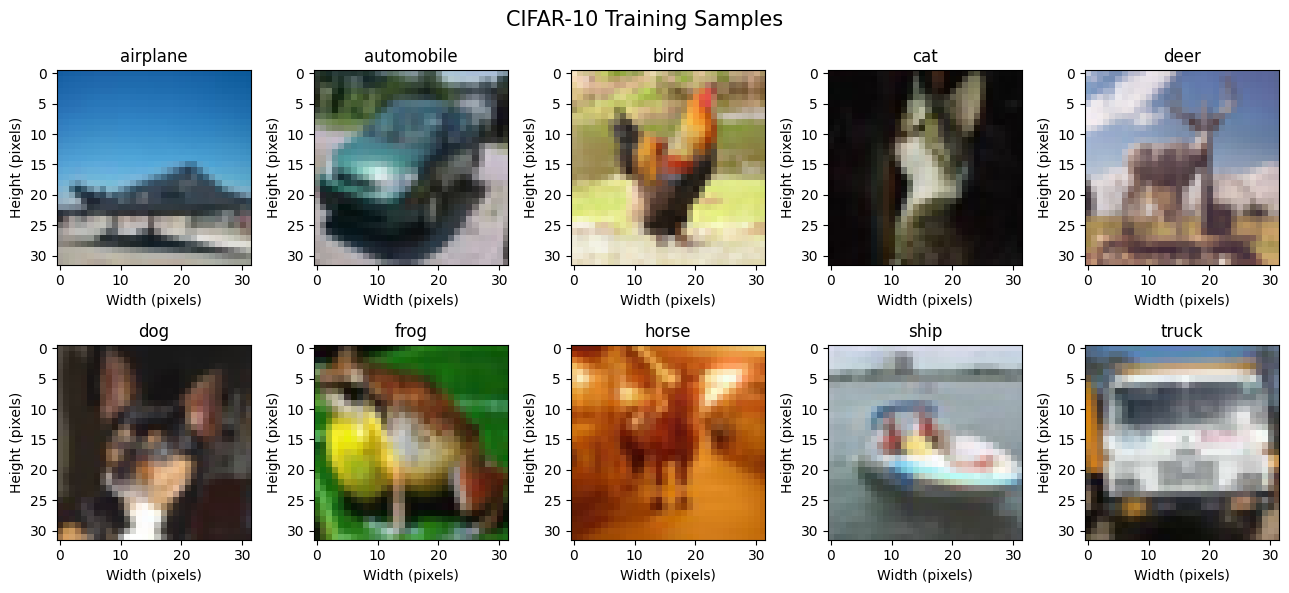

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(13, 6))

for class_id, ax in enumerate(axes.flat):
    idx = np.where(y_train == class_id)[0][0]

    ax.imshow(x_train[idx])
    ax.set_title(class_names[class_id])
    ax.set_xlabel("Width (pixels)")
    ax.set_ylabel("Height (pixels)")

plt.suptitle("CIFAR-10 Training Samples", fontsize=15)
plt.tight_layout()
plt.show()

## 3. Inception-style CNN architecture

In [5]:
def inception_module(x, filters=16):

    # Branch 1: 1x1 convolution
    branch1 = layers.Conv2D(
        filters, (1, 1),
        padding="same",
        activation="relu"
    )(x)

    # Branch 2: 1x1 reduction + 3x3 convolution
    branch2 = layers.Conv2D(
        filters, (1, 1),
        padding="same",
        activation="relu"
    )(x)

    branch2 = layers.Conv2D(
        filters, (3, 3),
        padding="same",
        activation="relu"
    )(branch2)

    # Branch 3: 1x1 reduction + 5x5 convolution
    branch3 = layers.Conv2D(
        filters, (1, 1),
        padding="same",
        activation="relu"
    )(x)

    branch3 = layers.Conv2D(
        filters, (5, 5),
        padding="same",
        activation="relu"
    )(branch3)

    # Combine the branches
    return layers.Concatenate()([
        branch1, branch2, branch3
    ])

In [6]:
def build_model():

    inputs = keras.Input(shape=(32, 32, 3))

    x = layers.Conv2D(
        32, (3, 3),
        padding="same",
        activation="relu"
    )(inputs)

    x = layers.BatchNormalization()(x)

    x = layers.MaxPooling2D((2, 2))(x)

    x = inception_module(x, filters=16)

    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.Conv2D(
        64, (3, 3),
        padding="same",
        activation="relu"
    )(x)

    x = layers.BatchNormalization()(x)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(
        64,
        activation="relu"
    )(x)

    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(
        10,
        activation="softmax"
    )(x)

    model = keras.Model(
        inputs=inputs,
        outputs=outputs
    )

    return model


model = build_model()
model.summary()

params = model.count_params()

print("Total parameters:", params)

assert params <= 1_000_000

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 32,    │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 32, 32,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 16, 16,    │        528 │ max_pooling2d[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │        528 │ max_pooling2d[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 16, 16,    │        528 │ max_pooling2d[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 16,    │      2,320 │ conv2d_2[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 16, 16,    │      6,416 │ conv2d_4[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ conv2d_1[0][0],   │
│ (Concatenate)       │ 48)               │            │ conv2d_3[0][0],   │
│                     │                   │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 8, 8, 48)  │          0 │ concatenate[0][0] │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 8, 8, 64)  │     27,712 │ max_pooling2d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 8, 64)  │        256 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      4,160 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 10)        │        650 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 44,122 (172.35 KB)

 Trainable params: 43,930 (171.60 KB)

 Non-trainable params: 192 (768.00 B)

Total parameters: 44122


## 4. Augmentation strategies and training infrastructure

In [7]:
def geometric_augmentation():
    return keras.Sequential([
        layers.ZeroPadding2D(padding=4),

        layers.RandomCrop(32, 32),

        # Ensure correct output size during training and validation
        layers.CenterCrop(32, 32),

        layers.RandomFlip("horizontal"),

        layers.RandomRotation(
            factor=25/360,
            fill_mode="reflect"
        )
    ])

In [8]:
from pathlib import Path

CHECKPOINT_DIR = Path("/content/checkpoints")
CHECKPOINT_DIR.mkdir(exist_ok=True)

def train_experiment(name, seed, augmentation_factory=None):

    keras.backend.clear_session()
    set_seed(seed)

    base_model = build_model()

    if augmentation_factory is not None:
        inputs = keras.Input(shape=(32, 32, 3))
        augmented = augmentation_factory()(inputs)
        outputs = base_model(augmented)
        model = keras.Model(inputs, outputs)
    else:
        model = base_model

    assert sum(
        int(np.prod(w.shape)) for w in model.trainable_weights
    ) <= 1_000_000

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    checkpoint_path = str(
        CHECKPOINT_DIR / f"{name}_seed_{seed}.weights.h5"
    )

    checkpoint = keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        save_weights_only=True,
        verbose=0
    )

    history = model.fit(
        x_train,
        y_train,
        validation_data=(x_val, y_val),
        epochs=60,
        batch_size=32,
        callbacks=[checkpoint],
        verbose=0
    )

    # Restore best validation checkpoint
    model.load_weights(checkpoint_path)

    train_loss, train_acc = model.evaluate(
        x_train, y_train, verbose=0
    )

    val_loss, val_acc = model.evaluate(
        x_val, y_val, verbose=0
    )

    best_epoch = (
        np.argmax(history.history["val_accuracy"]) + 1
    )

    print(
        f"{name} | Seed {seed} | "
        f"Best Epoch {best_epoch} | "
        f"Val Accuracy {val_acc*100:.2f}%"
    )

    return model, history, {
        "Configuration": name,
        "Seed": seed,
        "Best Epoch": best_epoch,
        "Train Accuracy": train_acc,
        "Val Accuracy": val_acc
    }

## 5. Baseline and geometric experiments (3 seeds each)

In [9]:
results = []
histories = {}
trained_models = {}

experiments = {
    "baseline": None,
    "geometric": geometric_augmentation
}

for name, aug_factory in experiments.items():
    for seed in SEEDS:

        model, history, result = train_experiment(
            name=name,
            seed=seed,
            augmentation_factory=aug_factory
        )

        results.append(result)
        histories[(name, seed)] = history
        trained_models[(name, seed)] = model

results_df = pd.DataFrame(results)

print("\nExperiment Results:")
print(results_df.to_string(index=False))

baseline | Seed 42 | Best Epoch 51 | Val Accuracy 42.00%
baseline | Seed 123 | Best Epoch 53 | Val Accuracy 37.00%
baseline | Seed 2026 | Best Epoch 60 | Val Accuracy 43.00%
geometric | Seed 42 | Best Epoch 51 | Val Accuracy 44.00%
geometric | Seed 123 | Best Epoch 53 | Val Accuracy 41.00%
geometric | Seed 2026 | Best Epoch 53 | Val Accuracy 45.00%

Experiment Results:
Configuration  Seed  Best Epoch  Train Accuracy  Val Accuracy
     baseline    42          51          0.9425          0.42
     baseline   123          53          0.7850          0.37
     baseline  2026          60          0.9775          0.43
    geometric    42          51          0.6150          0.44
    geometric   123          53          0.5525          0.41
    geometric  2026          53          0.6125          0.45


## 6. Photometric and combined augmentation

In [10]:
class RandomBlur(layers.Layer):

    def __init__(self, probability=0.4, **kwargs):
        super().__init__(**kwargs)
        self.probability = probability

    def call(self, inputs, training=None):

        def apply_blur():
            padded = tf.pad(
                inputs,
                [[0, 0], [1, 1], [1, 1], [0, 0]],
                mode="REFLECT"
            )

            blurred = tf.nn.avg_pool2d(
                padded,
                ksize=3,
                strides=1,
                padding="VALID"
            )

            mask = tf.random.uniform(
                (tf.shape(inputs)[0], 1, 1, 1)
            ) < self.probability

            return tf.where(mask, blurred, inputs)

        if training is False or training is None:
            return inputs

        if training is True:
            return apply_blur()

        return tf.cond(
            tf.cast(training, tf.bool),
            apply_blur,
            lambda: inputs
        )

In [11]:
def photometric_augmentation():

    return keras.Sequential([
        layers.RandomBrightness(
            factor=0.2,
            value_range=(0, 1)
        ),

        layers.RandomContrast(
            factor=0.2
        ),

        RandomBlur(probability=0.4),

        layers.GaussianNoise(0.035),

        layers.ReLU(max_value=1.0)
    ])

In [12]:
def combined_augmentation():

    return keras.Sequential([
        geometric_augmentation(),
        photometric_augmentation()
    ])

In [13]:
for name, factory in {
    "Photometric": photometric_augmentation,
    "Combined": combined_augmentation
}.items():

    aug = factory()

    train_output = aug(x_train[:4], training=True)
    val_output = aug(x_val[:4], training=False)

    print(name)
    print("Training shape:", train_output.shape)
    print("Validation shape:", val_output.shape)

    assert train_output.shape == (4, 32, 32, 3)
    assert val_output.shape == (4, 32, 32, 3)

    # Validation images should not be augmented
    assert np.allclose(val_output.numpy(), x_val[:4])

print("All augmentation checks passed.")

Photometric
Training shape: (4, 32, 32, 3)
Validation shape: (4, 32, 32, 3)
Combined
Training shape: (4, 32, 32, 3)
Validation shape: (4, 32, 32, 3)
All augmentation checks passed.


In [14]:
new_experiments = {
    "photometric": photometric_augmentation,
    "combined": combined_augmentation
}

for name, aug_factory in new_experiments.items():

    for seed in SEEDS:

        model, history, result = train_experiment(
            name=name,
            seed=seed,
            augmentation_factory=aug_factory
        )

        results.append(result)
        histories[(name, seed)] = history
        trained_models[(name, seed)] = model

results_df = pd.DataFrame(results)

summary = results_df.groupby(
    "Configuration"
)["Val Accuracy"].agg(["mean", "std"])

summary["Mean ± Std (%)"] = summary.apply(
    lambda row: (
        f"{row['mean']*100:.2f} ± "
        f"{row['std']*100:.2f}"
    ),
    axis=1
)

print(summary[["Mean ± Std (%)"]])

photometric | Seed 42 | Best Epoch 59 | Val Accuracy 42.00%
photometric | Seed 123 | Best Epoch 53 | Val Accuracy 43.00%
photometric | Seed 2026 | Best Epoch 42 | Val Accuracy 38.00%
combined | Seed 42 | Best Epoch 41 | Val Accuracy 42.00%
combined | Seed 123 | Best Epoch 53 | Val Accuracy 39.00%
combined | Seed 2026 | Best Epoch 33 | Val Accuracy 37.00%
              Mean ± Std (%)
Configuration               
baseline        40.67 ± 3.21
combined        39.33 ± 2.52
geometric       43.33 ± 2.08
photometric     41.00 ± 2.65


## 7. Cutout / Random Erasing

In [15]:
class RandomCutout(layers.Layer):

    def __init__(self, probability=0.5, patch_size=16, **kwargs):
        super().__init__(**kwargs)
        self.probability = probability
        self.patch_size = patch_size

    def call(self, inputs, training=None):

        def apply_cutout():

            shape = tf.shape(inputs)

            batch_size = shape[0]
            height = shape[1]
            width = shape[2]

            # Random position for each image
            top = tf.random.uniform(
                [batch_size, 1, 1, 1],
                minval=0,
                maxval=height - self.patch_size + 1,
                dtype=tf.int32
            )

            left = tf.random.uniform(
                [batch_size, 1, 1, 1],
                minval=0,
                maxval=width - self.patch_size + 1,
                dtype=tf.int32
            )

            rows = tf.reshape(
                tf.range(height), [1, -1, 1, 1]
            )

            cols = tf.reshape(
                tf.range(width), [1, 1, -1, 1]
            )

            patch = (
                (rows >= top) &
                (rows < top + self.patch_size) &
                (cols >= left) &
                (cols < left + self.patch_size)
            )

            # Apply to random images
            apply_mask = tf.random.uniform(
                [batch_size, 1, 1, 1]
            ) < self.probability

            erase_mask = patch & apply_mask

            return tf.where(
                erase_mask,
                tf.zeros_like(inputs),
                inputs
            )

        if training is None or training is False:
            return inputs

        if training is True:
            return apply_cutout()

        return tf.cond(
            tf.cast(training, tf.bool),
            apply_cutout,
            lambda: inputs
        )

In [16]:
def combined_cutout_augmentation():

    return keras.Sequential([
        geometric_augmentation(),
        photometric_augmentation(),
        RandomCutout(
            probability=0.5,
            patch_size=16
        )
    ])

In [17]:
cutout_aug = combined_cutout_augmentation()

train_output = cutout_aug(
    x_train[:4],
    training=True
)

val_output = cutout_aug(
    x_val[:4],
    training=False
)

print("Training shape:", train_output.shape)
print("Validation shape:", val_output.shape)

assert train_output.shape == (4, 32, 32, 3)
assert val_output.shape == (4, 32, 32, 3)

assert np.allclose(
    val_output.numpy(),
    x_val[:4]
)

print("Cutout augmentation checks passed.")

Training shape: (4, 32, 32, 3)
Validation shape: (4, 32, 32, 3)
Cutout augmentation checks passed.


In [18]:
# Avoid duplicate results if this cell is rerun
results = [
    r for r in results
    if r["Configuration"] != "combined_cutout"
]

for seed in SEEDS:

    model, history, result = train_experiment(
        name="combined_cutout",
        seed=seed,
        augmentation_factory=combined_cutout_augmentation
    )

    results.append(result)

    histories[("combined_cutout", seed)] = history

    trained_models[("combined_cutout", seed)] = model


results_df = pd.DataFrame(results)

summary = results_df.groupby(
    "Configuration"
)["Val Accuracy"].agg(["mean", "std"])

summary["Mean ± Std (%)"] = summary.apply(
    lambda row: (
        f"{row['mean'] * 100:.2f} ± "
        f"{row['std'] * 100:.2f}"
    ),
    axis=1
)

print(summary[["Mean ± Std (%)"]])

print("\nTotal completed runs:", len(results_df))

combined_cutout | Seed 42 | Best Epoch 52 | Val Accuracy 40.00%
combined_cutout | Seed 123 | Best Epoch 46 | Val Accuracy 36.00%
combined_cutout | Seed 2026 | Best Epoch 46 | Val Accuracy 39.00%
                Mean ± Std (%)
Configuration                 
baseline          40.67 ± 3.21
combined          39.33 ± 2.52
combined_cutout   38.33 ± 2.08
geometric         43.33 ± 2.08
photometric       41.00 ± 2.65

Total completed runs: 15


## 8. Mixup with label smoothing

In [19]:
def make_mixup_dataset(seed, alpha=0.2):

    dataset = tf.data.Dataset.from_tensor_slices(
        (x_train, y_train.astype(np.int32))
    )

    dataset = dataset.shuffle(
        buffer_size=len(x_train),
        seed=seed,
        reshuffle_each_iteration=True
    ).batch(32)

    def mix_batch(images, labels):

        labels = tf.one_hot(
            labels, depth=10, dtype=tf.float32
        )

        batch_size = tf.shape(images)[0]

        shuffled_indices = tf.random.shuffle(
            tf.range(batch_size)
        )

        images2 = tf.gather(
            images, shuffled_indices
        )

        labels2 = tf.gather(
            labels, shuffled_indices
        )

        # Sample lambda from Beta distribution
        gamma1 = tf.random.gamma([], alpha=alpha)
        gamma2 = tf.random.gamma([], alpha=alpha)

        lam = gamma1 / (gamma1 + gamma2 + 1e-7)

        mixed_images = (
            lam * images + (1 - lam) * images2
        )

        mixed_labels = (
            lam * labels + (1 - lam) * labels2
        )

        return mixed_images, mixed_labels

    dataset = dataset.map(
        mix_batch,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.prefetch(tf.data.AUTOTUNE)

In [20]:
def train_mixup_experiment(seed, epochs=60):

    keras.backend.clear_session()
    set_seed(seed)

    base_model = build_model()

    inputs = keras.Input(shape=(32, 32, 3))

    augmented = combined_cutout_augmentation()(inputs)

    outputs = base_model(augmented)

    model = keras.Model(inputs, outputs)

    trainable_params = sum(
        int(np.prod(w.shape))
        for w in model.trainable_weights
    )

    assert trainable_params <= 1_000_000

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss=keras.losses.CategoricalCrossentropy(
            label_smoothing=0.1
        ),
        metrics=[
            keras.metrics.CategoricalAccuracy(
                name="accuracy"
            )
        ]
    )

    train_ds = make_mixup_dataset(seed)

    y_val_onehot = keras.utils.to_categorical(
        y_val, num_classes=10
    )

    checkpoint_path = str(
        CHECKPOINT_DIR /
        f"combined_cutout_mixup_seed_{seed}.weights.h5"
    )

    checkpoint = keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        save_weights_only=True,
        verbose=0
    )

    history = model.fit(
        train_ds,
        validation_data=(x_val, y_val_onehot),
        epochs=epochs,
        callbacks=[checkpoint],
        verbose=0
    )

    model.load_weights(checkpoint_path)

    y_train_onehot = keras.utils.to_categorical(
        y_train, num_classes=10
    )

    train_loss, train_acc = model.evaluate(
        x_train,
        y_train_onehot,
        verbose=0
    )

    val_loss, val_acc = model.evaluate(
        x_val,
        y_val_onehot,
        verbose=0
    )

    best_epoch = (
        np.argmax(history.history["val_accuracy"]) + 1
    )

    print(
        f"Mixup | Seed {seed} | "
        f"Best Epoch {best_epoch} | "
        f"Val Accuracy {val_acc * 100:.2f}%"
    )

    return model, history, {
        "Configuration": "combined_cutout_mixup",
        "Seed": seed,
        "Best Epoch": best_epoch,
        "Train Accuracy": train_acc,
        "Val Accuracy": val_acc
    }

In [21]:
# Remove previous Mixup results if cell is rerun
results = [
    r for r in results
    if r["Configuration"] != "combined_cutout_mixup"
]

for seed in SEEDS:

    model, history, result = train_mixup_experiment(
        seed=seed,
        epochs=60
    )

    results.append(result)

    histories[("combined_cutout_mixup", seed)] = history

    trained_models[("combined_cutout_mixup", seed)] = model


results_df = pd.DataFrame(results)

summary = results_df.groupby(
    "Configuration"
)["Val Accuracy"].agg(["mean", "std"])

summary["Mean ± Std (%)"] = summary.apply(
    lambda row: (
        f"{row['mean'] * 100:.2f} ± "
        f"{row['std'] * 100:.2f}"
    ),
    axis=1
)

print(summary[["Mean ± Std (%)"]])

print("\nTotal completed runs:", len(results_df))

Mixup | Seed 42 | Best Epoch 60 | Val Accuracy 38.00%
Mixup | Seed 123 | Best Epoch 50 | Val Accuracy 38.00%
Mixup | Seed 2026 | Best Epoch 54 | Val Accuracy 37.00%
                      Mean ± Std (%)
Configuration                       
baseline                40.67 ± 3.21
combined                39.33 ± 2.52
combined_cutout         38.33 ± 2.08
combined_cutout_mixup   37.67 ± 0.58
geometric               43.33 ± 2.08
photometric             41.00 ± 2.65

Total completed runs: 18


## 9. Final regularized model

In [22]:
def train_final_model(seed, epochs=60):

    keras.backend.clear_session()
    set_seed(seed)

    base_model = build_model()

    inputs = keras.Input(shape=(32, 32, 3))

    augmented = geometric_augmentation()(inputs)

    outputs = base_model(augmented)

    model = keras.Model(inputs, outputs)

    trainable_params = sum(
        int(np.prod(w.shape))
        for w in model.trainable_weights
    )

    assert trainable_params <= 1_000_000

    model.compile(
        optimizer=keras.optimizers.AdamW(
            learning_rate=0.001,
            weight_decay=0.0001
        ),

        loss=keras.losses.CategoricalCrossentropy(
            label_smoothing=0.05
        ),

        metrics=[
            keras.metrics.CategoricalAccuracy(
                name="accuracy"
            )
        ]
    )

    y_train_onehot = keras.utils.to_categorical(
        y_train, num_classes=10
    )

    y_val_onehot = keras.utils.to_categorical(
        y_val, num_classes=10
    )

    checkpoint_path = str(
        CHECKPOINT_DIR /
        f"final_model_seed_{seed}.weights.h5"
    )

    callbacks = [

        keras.callbacks.ModelCheckpoint(
            filepath=checkpoint_path,
            monitor="val_accuracy",
            mode="max",
            save_best_only=True,
            save_weights_only=True,
            verbose=0
        ),

        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=10,
            min_lr=0.00001,
            verbose=0
        ),

        keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            mode="max",
            patience=15,
            start_from_epoch=35,
            verbose=0
        )
    ]

    history = model.fit(
        x_train,
        y_train_onehot,
        validation_data=(x_val, y_val_onehot),
        epochs=epochs,
        batch_size=32,
        callbacks=callbacks,
        verbose=0
    )

    # Restore the best validation checkpoint
    model.load_weights(checkpoint_path)

    train_loss, train_acc = model.evaluate(
        x_train,
        y_train_onehot,
        verbose=0
    )

    val_loss, val_acc = model.evaluate(
        x_val,
        y_val_onehot,
        verbose=0
    )

    best_epoch = (
        np.argmax(history.history["val_accuracy"]) + 1
    )

    print(
        f"Final Model | Seed {seed} | "
        f"Best Epoch {best_epoch} | "
        f"Val Accuracy {val_acc * 100:.2f}%"
    )

    return model, history, {
        "Configuration": "final_model",
        "Seed": seed,
        "Best Epoch": best_epoch,
        "Train Accuracy": train_acc,
        "Val Accuracy": val_acc
    }

In [23]:
# Remove old final-model results if rerunning
results = [
    r for r in results
    if r["Configuration"] != "final_model"
]

for seed in SEEDS:

    model, history, result = train_final_model(
        seed=seed,
        epochs=60
    )

    results.append(result)

    histories[("final_model", seed)] = history

    trained_models[("final_model", seed)] = model


results_df = pd.DataFrame(results)

print("\nFinal Experiment Results:")
print(results_df.to_string(index=False))

print("\nTotal completed runs:", len(results_df))

Final Model | Seed 42 | Best Epoch 59 | Val Accuracy 44.00%
Final Model | Seed 123 | Best Epoch 60 | Val Accuracy 40.00%
Final Model | Seed 2026 | Best Epoch 57 | Val Accuracy 46.00%

Final Experiment Results:
        Configuration  Seed  Best Epoch  Train Accuracy  Val Accuracy
             baseline    42          51          0.9425          0.42
             baseline   123          53          0.7850          0.37
             baseline  2026          60          0.9775          0.43
            geometric    42          51          0.6150          0.44
            geometric   123          53          0.5525          0.41
            geometric  2026          53          0.6125          0.45
          photometric    42          59          0.9100          0.42
          photometric   123          53          0.8750          0.43
          photometric  2026          42          0.6400          0.38
             combined    42          41          0.4450          0.42
             combine

In [24]:
summary = results_df.groupby(
    "Configuration"
)["Val Accuracy"].agg(["mean", "std"])

summary["Mean ± Std (%)"] = summary.apply(
    lambda row: (
        f"{row['mean'] * 100:.2f} ± "
        f"{row['std'] * 100:.2f}"
    ),
    axis=1
)

print(summary[["Mean ± Std (%)"]])

best_config = summary["mean"].idxmax()

print("\nBest validation configuration:", best_config)
print(
    "Mean validation accuracy:",
    f"{summary.loc[best_config, 'mean'] * 100:.2f}%"
)

                      Mean ± Std (%)
Configuration                       
baseline                40.67 ± 3.21
combined                39.33 ± 2.52
combined_cutout         38.33 ± 2.08
combined_cutout_mixup   37.67 ± 0.58
final_model             43.33 ± 3.06
geometric               43.33 ± 2.08
photometric             41.00 ± 2.65

Best validation configuration: final_model
Mean validation accuracy: 43.33%


## 10. Export results and checkpoints (local runtime)

In [25]:
from pathlib import Path
import shutil

# Portable storage: no Google Drive account/mount required.
backup_dir = Path("/content/DLP_Assignment2_Results")
backup_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(backup_dir / "validation_results.csv", index=False)
np.savez(backup_dir / "dataset_split.npz",
         train_indices=train_indices, val_indices=val_indices)

destination = backup_dir / "checkpoints"
shutil.copytree(CHECKPOINT_DIR, destination, dirs_exist_ok=True)
print("Local results saved:", backup_dir)
print("Saved checkpoints:", len(list(destination.glob("*.weights.h5"))))


Local results saved: /content/DLP_Assignment2_Results
Saved checkpoints: 21


## 11. Simulated corruption test sets

In [26]:
import cv2

SHIFT_SEED = 314159

def generate_shifted_test(images, seed=SHIFT_SEED):

    rng = np.random.default_rng(seed)

    shifted = np.empty(
        images.shape,
        dtype=np.float32
    )

    for i, original in enumerate(images):

        img = original.astype(np.float32).copy()

        h, w = img.shape[:2]

        # Rotation: up to +/- 25 degrees
        angle = rng.uniform(-25, 25)

        matrix = cv2.getRotationMatrix2D(
            (w / 2, h / 2),
            angle,
            1.0
        )

        img = cv2.warpAffine(
            img,
            matrix,
            (w, h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_REFLECT_101
        )

        # Brightness and contrast
        if rng.random() < 0.75:

            alpha = rng.uniform(0.75, 1.25)
            beta = rng.uniform(-25, 25)

            img = img * alpha + beta

        img = np.clip(img, 0, 255)

        # Gaussian blur
        if rng.random() < 0.40:

            img = cv2.GaussianBlur(
                img, (3, 3), sigmaX=0.8
            )

        # Gaussian noise
        if rng.random() < 0.40:

            noise = rng.normal(
                0, 12, img.shape
            )

            img = img + noise

        img = np.clip(img, 0, 255)

        # Random rectangular occlusion (25%)
        if rng.random() < 0.50:

            patch_size = 16

            top = rng.integers(
                0, h - patch_size + 1
            )

            left = rng.integers(
                0, w - patch_size + 1
            )

            img[
                top:top + patch_size,
                left:left + patch_size
            ] = 0

        # Assumed hidden corruption: grayscale
        if rng.random() < 0.25:

            gray = cv2.cvtColor(
                img.astype(np.uint8),
                cv2.COLOR_RGB2GRAY
            )

            img = np.repeat(
                gray[:, :, None],
                3,
                axis=2
            )

        shifted[i] = (
            np.clip(img, 0, 255) / 255.0
        )

    return shifted


x_clean_test = (
    x_test.astype(np.float32) / 255.0
)

x_shifted_test = generate_shifted_test(x_test)

assert x_clean_test.shape == (10000, 32, 32, 3)
assert x_shifted_test.shape == (10000, 32, 32, 3)

print("Clean test:", x_clean_test.shape)
print("Shifted test:", x_shifted_test.shape)
print("Shifted dataset generated successfully.")

Clean test: (10000, 32, 32, 3)
Shifted test: (10000, 32, 32, 3)
Shifted dataset generated successfully.


## 12. One-time clean/shifted test evaluation

In [27]:
configurations = [
    "baseline",
    "geometric",
    "photometric",
    "combined",
    "combined_cutout",
    "combined_cutout_mixup",
    "final_model"
]

# Ensure all trained models are available
for config in configurations:
    for seed in SEEDS:
        assert (config, seed) in trained_models, (
            f"Missing model: {config}, seed {seed}"
        )

test_records = []

for config in configurations:

    for seed in SEEDS:

        model = trained_models[(config, seed)]

        clean_predictions = model.predict(
            x_clean_test,
            batch_size=256,
            verbose=0
        )

        shifted_predictions = model.predict(
            x_shifted_test,
            batch_size=256,
            verbose=0
        )

        clean_acc = np.mean(
            np.argmax(clean_predictions, axis=1) == y_test
        )

        shifted_acc = np.mean(
            np.argmax(shifted_predictions, axis=1) == y_test
        )

        test_records.append({
            "Configuration": config,
            "Seed": seed,
            "Clean Accuracy": clean_acc,
            "Shifted Accuracy": shifted_acc
        })

        print(
            f"{config} | Seed {seed} | "
            f"Clean: {clean_acc*100:.2f}% | "
            f"Shifted: {shifted_acc*100:.2f}%"
        )

test_df = pd.DataFrame(test_records)

full_results = results_df.merge(
    test_df,
    on=["Configuration", "Seed"],
    validate="one_to_one"
)

assert len(full_results) == 21

full_results.to_csv(
    backup_dir / "all_experiment_results.csv",
    index=False
)

print("\nAll 21 models evaluated successfully.")

baseline | Seed 42 | Clean: 37.30% | Shifted: 20.86%
baseline | Seed 123 | Clean: 31.01% | Shifted: 20.40%
baseline | Seed 2026 | Clean: 39.27% | Shifted: 22.29%
geometric | Seed 42 | Clean: 36.40% | Shifted: 26.72%
geometric | Seed 123 | Clean: 34.69% | Shifted: 24.31%
geometric | Seed 2026 | Clean: 34.95% | Shifted: 22.08%
photometric | Seed 42 | Clean: 38.54% | Shifted: 28.18%
photometric | Seed 123 | Clean: 34.37% | Shifted: 25.63%
photometric | Seed 2026 | Clean: 34.28% | Shifted: 24.09%
combined | Seed 42 | Clean: 33.15% | Shifted: 24.48%
combined | Seed 123 | Clean: 35.89% | Shifted: 26.50%
combined | Seed 2026 | Clean: 30.74% | Shifted: 22.46%
combined_cutout | Seed 42 | Clean: 35.61% | Shifted: 30.05%
combined_cutout | Seed 123 | Clean: 32.98% | Shifted: 27.36%
combined_cutout | Seed 2026 | Clean: 33.85% | Shifted: 28.08%
combined_cutout_mixup | Seed 42 | Clean: 37.61% | Shifted: 32.38%
combined_cutout_mixup | Seed 123 | Clean: 35.73% | Shifted: 29.66%
combined_cutout_mixup | 

In [28]:
table_rows = []

for config in configurations:

    group = full_results[
        full_results["Configuration"] == config
    ]

    def mean_std(column):
        values = group[column].to_numpy()
        return (
            f"{np.mean(values)*100:.2f} ± "
            f"{np.std(values, ddof=1)*100:.2f}%"
        )

    table_rows.append({
        "Configuration": config,
        "Val Acc": mean_std("Val Accuracy"),
        "Clean Test": mean_std("Clean Accuracy"),
        "Shifted Test": mean_std("Shifted Accuracy")
    })

ablation_table = pd.DataFrame(table_rows)

print("\nCOMPLETE ABLATION STUDY")
print(ablation_table.to_string(index=False))

ablation_table.to_csv(
    backup_dir / "ablation_table.csv",
    index=False
)


COMPLETE ABLATION STUDY
        Configuration       Val Acc    Clean Test  Shifted Test
             baseline 40.67 ± 3.21% 35.86 ± 4.31% 21.18 ± 0.99%
            geometric 43.33 ± 2.08% 35.35 ± 0.92% 24.37 ± 2.32%
          photometric 41.00 ± 2.65% 35.73 ± 2.43% 25.97 ± 2.07%
             combined 39.33 ± 2.52% 33.26 ± 2.58% 24.48 ± 2.02%
      combined_cutout 38.33 ± 2.08% 34.15 ± 1.34% 28.50 ± 1.39%
combined_cutout_mixup 37.67 ± 0.58% 36.49 ± 0.99% 30.49 ± 1.64%
          final_model 43.33 ± 3.06% 37.59 ± 2.51% 27.27 ± 0.54%


## 13. Selected model and error analysis

In [29]:
selected_config = "geometric"

geo_results = results_df[
    results_df["Configuration"] == selected_config
]

best_row = geo_results.loc[
    geo_results["Val Accuracy"].idxmax()
]

best_seed = int(best_row["Seed"])

selected_model = trained_models[
    (selected_config, best_seed)
]

print("Selected configuration:", selected_config)
print("Selected seed:", best_seed)
print("Validation accuracy:",
      f"{best_row['Val Accuracy'] * 100:.2f}%")

pred_clean = np.argmax(
    selected_model.predict(
        x_clean_test, batch_size=256, verbose=0
    ),
    axis=1
)

pred_shifted = np.argmax(
    selected_model.predict(
        x_shifted_test, batch_size=256, verbose=0
    ),
    axis=1
)

Selected configuration: geometric
Selected seed: 2026
Validation accuracy: 45.00%


     Class  Clean Accuracy  Shifted Accuracy
  airplane            53.3              41.4
automobile            49.6              21.0
      bird            18.1              45.0
       cat            10.3               7.6
      deer            37.7              18.1
       dog            14.3               6.0
      frog            42.1              13.6
     horse            26.2               8.4
      ship            69.1              47.8
     truck            28.8              11.9


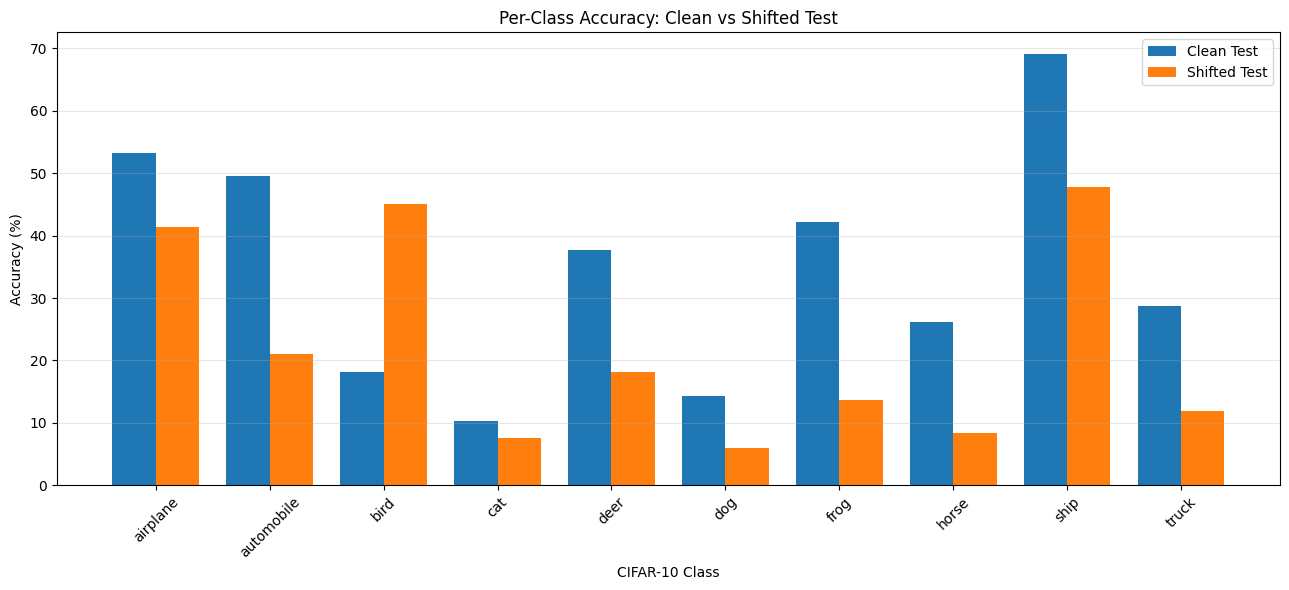

In [30]:
class_results = []

for i, name in enumerate(class_names):

    mask = (y_test == i)

    clean_accuracy = np.mean(
        pred_clean[mask] == y_test[mask]
    )

    shifted_accuracy = np.mean(
        pred_shifted[mask] == y_test[mask]
    )

    class_results.append({
        "Class": name,
        "Clean Accuracy": clean_accuracy * 100,
        "Shifted Accuracy": shifted_accuracy * 100
    })

class_df = pd.DataFrame(class_results)

print(class_df.to_string(index=False))

# Plot
x = np.arange(len(class_names))
width = 0.38

plt.figure(figsize=(13, 6))

plt.bar(
    x - width/2,
    class_df["Clean Accuracy"],
    width,
    label="Clean Test"
)

plt.bar(
    x + width/2,
    class_df["Shifted Accuracy"],
    width,
    label="Shifted Test"
)

plt.xticks(x, class_names, rotation=45)
plt.xlabel("CIFAR-10 Class")
plt.ylabel("Accuracy (%)")
plt.title("Per-Class Accuracy: Clean vs Shifted Test")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

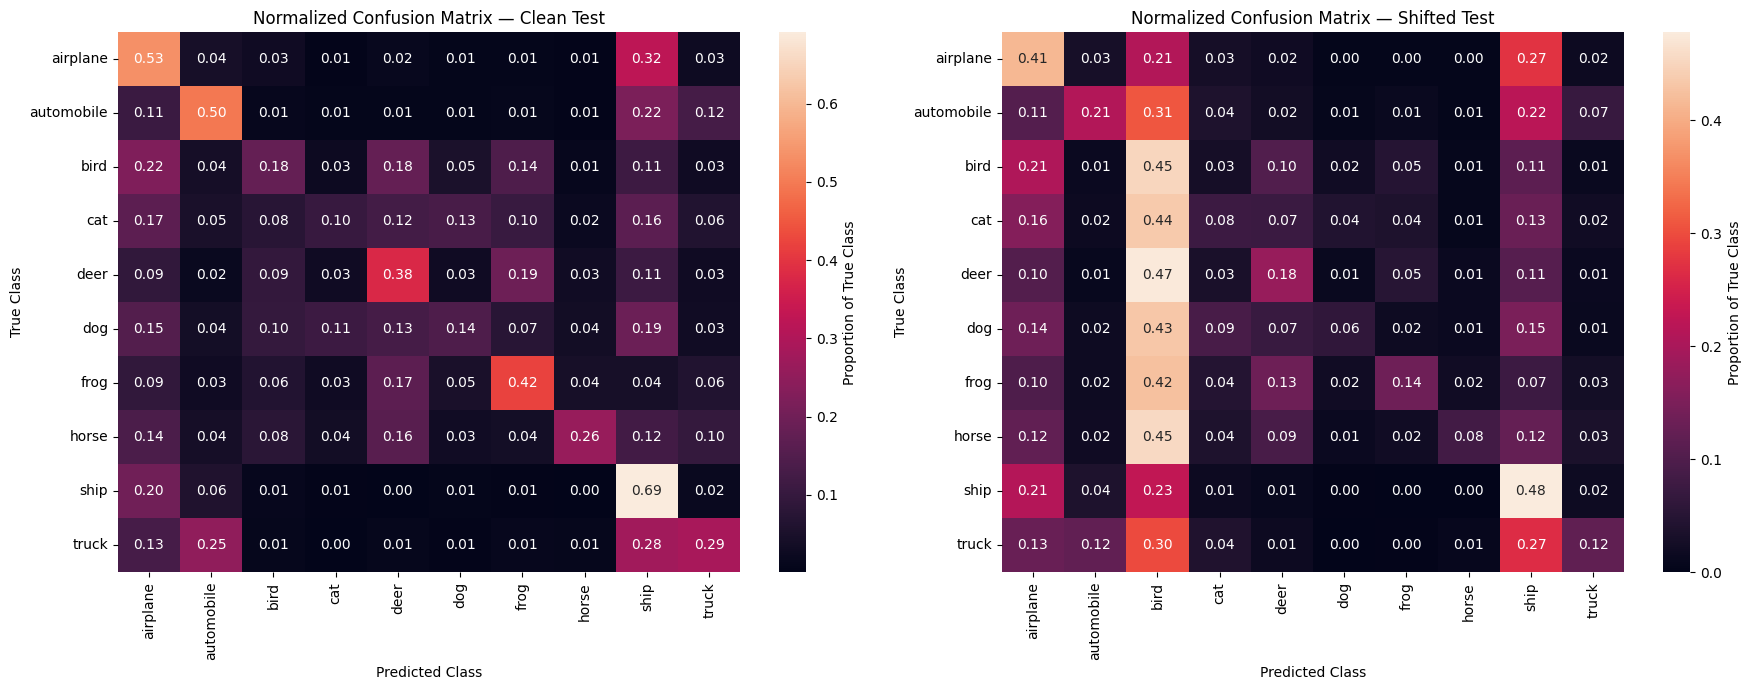


Top 5 Most Confused Class Pairs:
deer → bird: 475 images
horse → bird: 454 images
cat → bird: 436 images
dog → bird: 433 images
frog → bird: 425 images


In [31]:
cm_clean = confusion_matrix(
    y_test, pred_clean, labels=np.arange(10)
)

cm_shifted = confusion_matrix(
    y_test, pred_shifted, labels=np.arange(10)
)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, cm, title in zip(
    axes,
    [cm_clean, cm_shifted],
    ["Clean Test", "Shifted Test"]
):

    cm_normalized = (
        cm / cm.sum(axis=1, keepdims=True)
    )

    sns.heatmap(
        cm_normalized,
        annot=True,
        fmt=".2f",
        xticklabels=class_names,
        yticklabels=class_names,
        cbar=True,
        cbar_kws={"label": "Proportion of True Class"},
        ax=ax
    )

    ax.set_title(f"Normalized Confusion Matrix — {title}")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")

plt.tight_layout()
plt.show()

# Identify most confused classes
confusions = [
    (cm_shifted[i, j], i, j)
    for i in range(10)
    for j in range(10)
    if i != j
]

confusions.sort(reverse=True)

print("\nTop 5 Most Confused Class Pairs:")

for count, true_id, pred_id in confusions[:5]:
    print(
        f"{class_names[true_id]} → "
        f"{class_names[pred_id]}: {count} images"
    )

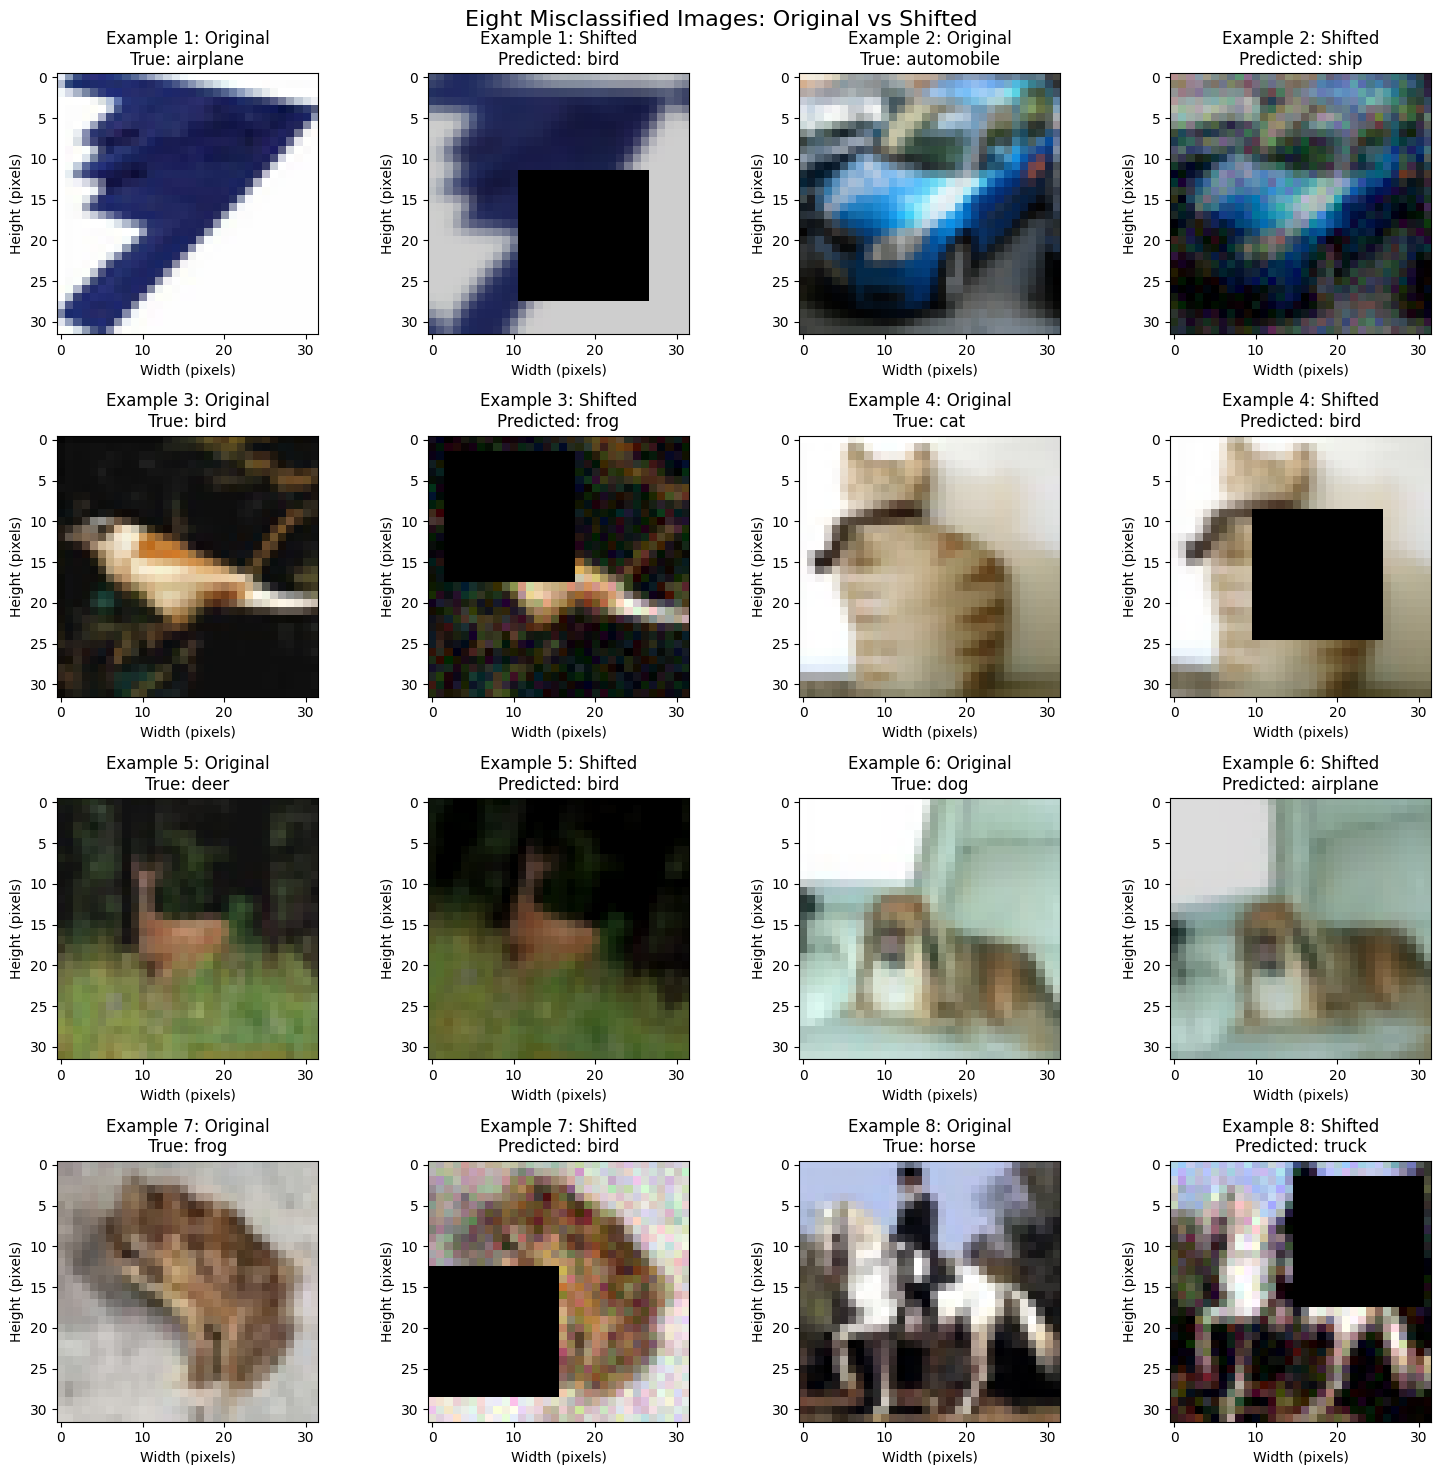


Misclassified examples:
1. True: airplane | Predicted: bird
2. True: automobile | Predicted: ship
3. True: bird | Predicted: frog
4. True: cat | Predicted: bird
5. True: deer | Predicted: bird
6. True: dog | Predicted: airplane
7. True: frog | Predicted: bird
8. True: horse | Predicted: truck


In [32]:
rng_errors = np.random.default_rng(2026)

selected_errors = []

for class_id in range(10):

    candidates = np.where(
        (y_test == class_id) &
        (pred_shifted != y_test)
    )[0]

    if len(candidates) > 0:
        selected_errors.append(
            int(rng_errors.choice(candidates))
        )

    if len(selected_errors) == 8:
        break

assert len(selected_errors) == 8

fig, axes = plt.subplots(4, 4, figsize=(15, 15))

for k, idx in enumerate(selected_errors):

    row = k // 2
    col = (k % 2) * 2

    ax_clean = axes[row, col]
    ax_shift = axes[row, col + 1]

    ax_clean.imshow(x_clean_test[idx])
    ax_clean.set_title(
        f"Example {k+1}: Original\n"
        f"True: {class_names[y_test[idx]]}"
    )

    ax_shift.imshow(x_shifted_test[idx])
    ax_shift.set_title(
        f"Example {k+1}: Shifted\n"
        f"Predicted: {class_names[pred_shifted[idx]]}"
    )

    for ax in [ax_clean, ax_shift]:
        ax.set_xlabel("Width (pixels)")
        ax.set_ylabel("Height (pixels)")

plt.suptitle(
    "Eight Misclassified Images: Original vs Shifted",
    fontsize=16
)

plt.tight_layout()
plt.show()

print("\nMisclassified examples:")

for n, idx in enumerate(selected_errors, start=1):
    print(
        f"{n}. True: {class_names[y_test[idx]]} | "
        f"Predicted: {class_names[pred_shifted[idx]]}"
    )

In [33]:
# Only grayscale corruption
gray = tf.image.rgb_to_grayscale(x_clean_test)

x_hidden_only = tf.repeat(
    gray, repeats=3, axis=-1
).numpy()

assert x_hidden_only.shape == x_clean_test.shape

hidden_results = []

for config in ["baseline", "geometric"]:

    for seed in SEEDS:

        model = trained_models[(config, seed)]

        predictions = np.argmax(
            model.predict(
                x_hidden_only,
                batch_size=256,
                verbose=0
            ),
            axis=1
        )

        accuracy = np.mean(
            predictions == y_test
        )

        hidden_results.append({
            "Configuration": config,
            "Seed": seed,
            "Hidden Accuracy": accuracy
        })

hidden_df = pd.DataFrame(hidden_results)

hidden_summary = hidden_df.groupby(
    "Configuration"
)["Hidden Accuracy"].agg(["mean", "std"])

for name, row in hidden_summary.iterrows():
    print(
        f"{name}: "
        f"{row['mean']*100:.2f} ± "
        f"{row['std']*100:.2f}%"
    )

baseline: 27.90 ± 3.98%
geometric: 26.01 ± 3.80%


## 14. Visual reports and learning curves

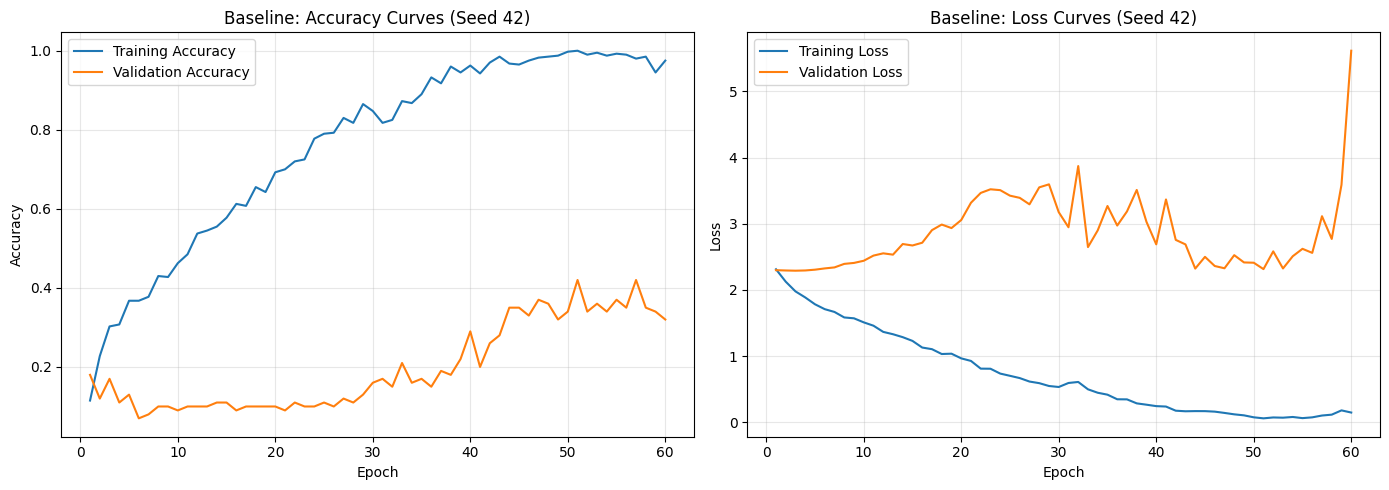

In [34]:
h = histories[("baseline", 42)].history

epochs = range(1, len(h["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    epochs, h["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    epochs, h["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].set_title("Baseline: Accuracy Curves (Seed 42)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    epochs, h["loss"],
    label="Training Loss"
)

axes[1].plot(
    epochs, h["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("Baseline: Loss Curves (Seed 42)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    backup_dir / "baseline_learning_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

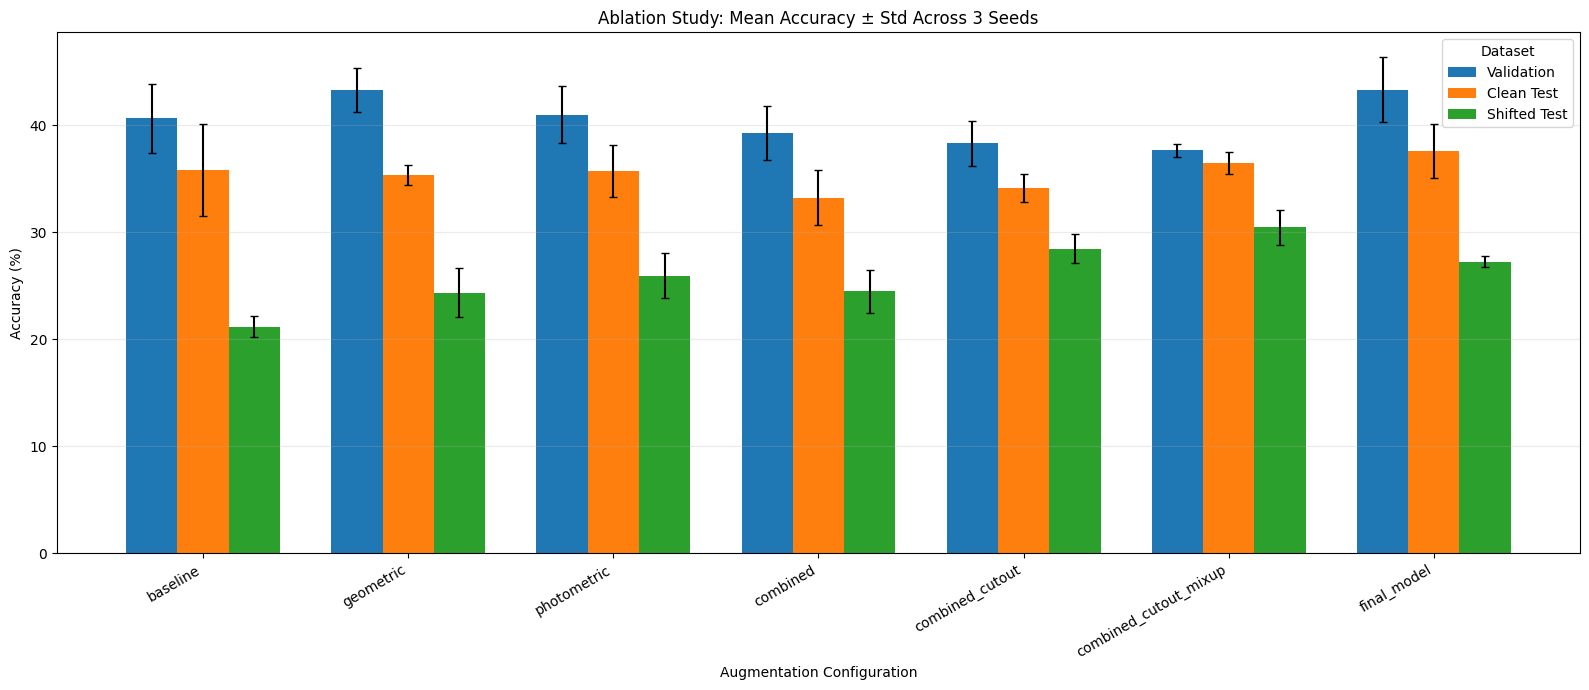

In [35]:
configs = [
    "baseline",
    "geometric",
    "photometric",
    "combined",
    "combined_cutout",
    "combined_cutout_mixup",
    "final_model"
]

metrics = {
    "Val Accuracy": "Validation",
    "Clean Accuracy": "Clean Test",
    "Shifted Accuracy": "Shifted Test"
}

x = np.arange(len(configs))
width = 0.25

fig, ax = plt.subplots(figsize=(16, 7))

for i, (column, label) in enumerate(metrics.items()):

    means = []
    stds = []

    for config in configs:
        values = full_results.loc[
            full_results["Configuration"] == config,
            column
        ].to_numpy()

        means.append(values.mean() * 100)
        stds.append(values.std(ddof=1) * 100)

    ax.bar(
        x + (i - 1) * width,
        means,
        width,
        yerr=stds,
        capsize=3,
        label=label
    )

ax.set_xticks(x)
ax.set_xticklabels(configs, rotation=30, ha="right")

ax.set_xlabel("Augmentation Configuration")
ax.set_ylabel("Accuracy (%)")
ax.set_title(
    "Ablation Study: Mean Accuracy ± Std Across 3 Seeds"
)
ax.legend(title="Dataset")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    backup_dir / "ablation_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### Reproducibility and evaluation notes
- Only the 400-image training split is used for fitting; 100 separate images are used for validation and model selection.
- The code selects the geometric configuration on validation performance, not using test results.
- The simulated shifted set uses documented, locally chosen corruption intensities and a grayscale assumption; it must not be described as the exact instructor hidden corruption.
- Checkpoints and CSV files are written under `/content/DLP_Assignment2_Results`. Download them from Colab if you want persistent copies; Colab's `/content` storage is temporary.
- The displayed saved outputs originated from the original notebook execution and may differ after fresh execution due to environment versions and randomness.


## 15. Written discussion — Parts A–E


# Section B — Results, Explanations and Discussion

## Experiment Overview

This experiment investigates robust image classification using a limited training subset of CIFAR-10. The objective is to improve model generalization under image corruption using data augmentation, regularization, and an Inception-style CNN architecture.

The model was developed using TensorFlow/Keras and trained entirely from scratch without pretrained weights.

### Experimental Setup

| Parameter | Value |
|---|---|
| Dataset | CIFAR-10 |
| Selected Training Images | 500 (50 per class) |
| Actual Training Images | 400 (40 per class) |
| Validation Images | 100 (10 per class) |
| Clean Test Images | 10,000 |
| Shifted Test Images | 10,000 |
| Image Resolution | 32 × 32 × 3 |
| Number of Classes | 10 |
| Model Architecture | Custom CNN with Inception-style Module |
| Total Parameters | 44,122 |
| Trainable Parameters | 43,930 |
| Maximum Allowed Parameters | 1,000,000 |
| Maximum Training Epochs | 60 |
| Batch Size | 32 |
| Random Seeds | 42, 123, 2026 |
| Framework | TensorFlow/Keras |

The CNN contains an Inception-style module with parallel 1×1, 3×3, and 5×5 convolutional branches. The 3×3 and 5×5 branches use 1×1 reductions. Batch Normalization, Global Average Pooling, and Dropout were also incorporated.

A fixed-seed simulated shifted-test dataset was generated from the original CIFAR-10 test images using rotation, brightness and contrast adjustments, Gaussian blur, noise, rectangular occlusion, and an assumed grayscale corruption.

The exact instructor-provided hidden corruption was not specified. Therefore, the shifted-test results represent the locally generated corruption setting rather than a verified official hidden test set.

---

# Part A — Baseline

## A.1 Baseline Results

The baseline CNN was trained using 400 clean CIFAR-10 images without data augmentation. Three random seeds were used to measure variation in model performance.

| Metric | Result |
|---|---|
| Validation Accuracy | 40.67 ± 3.21% |
| Clean-Test Accuracy | 35.86 ± 4.31% |
| Shifted-Test Accuracy | 21.18 ± 0.99% |

The baseline learning curves showed that training accuracy increased considerably during training, while validation accuracy remained relatively low.

## A.2 Overfitting and Covariate Shift

The baseline achieved 35.86% clean-test accuracy and 21.18% shifted-test accuracy, representing a decrease of 14.68 percentage points.

The large gap between training and validation accuracy indicates overfitting because the model learned the limited training examples but struggled to generalize to unseen images.

The additional decrease on shifted images indicates covariate shift caused by rotation, changes in illumination, blur, Gaussian noise, and occlusion.

Therefore, both overfitting and covariate shift contributed to the poor generalization performance.

---

# Part B — Data Augmentation Strategy

## B.1 Selected Augmentation Techniques and Justification

### 1. Geometric Augmentation

Geometric augmentation included random cropping, horizontal flipping, and rotation up to approximately ±25°.

These transformations increase spatial diversity and encourage the model to recognize objects despite moderate changes in position and orientation.

Geometric augmentation achieved a mean validation accuracy of 43.33%, compared with 40.67% for the baseline.

### 2. Photometric Augmentation

Photometric augmentation included brightness changes, contrast adjustments, Gaussian blur, and Gaussian noise.

These transformations help the model learn features that are less dependent on particular lighting conditions, colors, or image quality.

Photometric augmentation improved shifted-test accuracy from 21.18% to 25.97%, an improvement of 4.79 percentage points.

### 3. Cutout / Random Erasing

Cutout removes a randomly positioned rectangular region from an image during training.

A 16×16 pixel patch was used with a probability of 0.5. The patch represents 25% of a 32×32 image.

This encourages the model to recognize objects using multiple visible regions rather than depending on a single discriminative feature.

Adding Cutout to combined augmentation improved shifted-test accuracy from 24.48% to 28.50%, a gain of 4.02 percentage points.

### 4. Mixup and Label Smoothing

Mixup combines two training images and their corresponding labels using a randomly sampled mixing coefficient.

This generates additional training examples and encourages smoother classification boundaries.

Label smoothing reduces excessive prediction confidence by distributing a small amount of probability across other classes.

Adding Mixup with label smoothing increased shifted-test accuracy from 28.50% to 30.49%, an improvement of 1.99 percentage points.

## B.2 Theoretical Questions

### Question 1: Would vertical flipping help or hurt on CIFAR-10? Why?

Vertical flipping would generally hurt classification performance because most CIFAR-10 objects appear in their natural orientation.

Flipping cars, trucks, animals, and ships upside down creates unrealistic images that rarely appear in ordinary real-world scenes.

These transformations could confuse the model and reduce its ability to learn meaningful features.

Therefore, horizontal flipping is generally more appropriate than vertical flipping for CIFAR-10.

### Question 2: If augmentation uses rotations up to ±90° but the test images contain only ±25° rotations, what is the trade-off?

Using rotations up to ±90° increases training diversity and may improve rotation invariance.

However, extreme rotations can create unrealistic object orientations, making the classification problem unnecessarily difficult.

Since the shifted-test images contain rotations up to approximately ±25°, using significantly larger rotations may introduce unnecessary variation and reduce accuracy.

Therefore, moderate rotations provide a balance between robustness and preserving realistic image appearances.

### Question 3: Why can too much augmentation reduce accuracy on such a small model?

Excessive augmentation may distort important object features and generate unrealistic training samples.

With only 400 training images and a relatively small CNN, the model has limited capacity to learn from heavily transformed images.

Strong augmentation may make the task too difficult and cause underfitting.

This behavior was observed in our experiments, where geometric augmentation achieved 43.33% validation accuracy, while combined geometric and photometric augmentation achieved only 39.33%.

Therefore, augmentation strength must be balanced with dataset size, model capacity, and the target distribution.

---

# Part C — Regularization and Training Design

## C.1 Batch Normalization

Batch Normalization was applied after convolutional layers to stabilize intermediate feature activations and support optimization.

It helps control changes in the distributions of intermediate activations and can improve training convergence.

It was placed after convolutional layers because these layers generate the feature maps used throughout the network.

## C.2 Dropout

Dropout with a rate of 0.4 was applied after the fully connected hidden layer.

It randomly disables some neuron outputs during training, reducing excessive dependence on individual neurons.

Dropout was not placed between early convolutional layers because these layers extract low-level features such as edges, corners, and textures.

Aggressive dropout in early layers could disrupt important spatial feature information.

## C.3 Weight Decay

The final regularized model used the AdamW optimizer with a weight decay coefficient of 0.0001.

Weight decay discourages excessively large model weights and can reduce overfitting by limiting model complexity.

This is particularly relevant because only 400 images were available for training.

## C.4 Learning Rate Scheduling

ReduceLROnPlateau was used in the final regularized model.

The learning rate was reduced when validation loss stopped improving, allowing smaller optimization steps during later epochs.

This technique can improve convergence and reduce oscillations during training.

## C.5 Early Stopping

Early stopping was used to prevent unnecessary training when validation accuracy stopped improving.

The maximum allowed training duration was 60 epochs, and the best validation checkpoint was saved for final evaluation.

The final regularized model used patience of 15 epochs, with early stopping monitoring beginning after epoch 35.

This provided sufficient training time before early stopping could terminate the run.

## C.6 Label Smoothing

Label smoothing was applied to reduce overconfident predictions.

A smoothing factor of 0.1 was used with Mixup, while 0.05 was used in the final regularized model.

Label smoothing discourages the model from assigning complete confidence to a single class.

## C.7 Regularization Results

The final regularized model used geometric augmentation, Batch Normalization, Dropout, AdamW weight decay, learning-rate scheduling, early stopping, and label smoothing.

It achieved the following results:

| Metric | Accuracy |
|---|---|
| Validation | 43.33 ± 3.06% |
| Clean Test | 37.59 ± 2.51% |
| Shifted Test | 27.27 ± 0.54% |

The final regularized model achieved the same mean validation accuracy as geometric augmentation (43.33%), but showed greater variation across the three seeds.

The final regularized model also achieved higher mean clean-test and shifted-test accuracies.

However, geometric augmentation remained the selected configuration based on validation performance and consistency across seeds.

---

# Part D — Ablation Study

## D.1 Complete Ablation Study Results

Seven training configurations were evaluated using three random seeds.

All reported results represent mean accuracy ± sample standard deviation.

| Configuration | Val Accuracy | Clean Test | Shifted Test |
|---|---|---|---|
| No Augmentation | 40.67 ± 3.21% | 35.86 ± 4.31% | 21.18 ± 0.99% |
| Geometric Only | 43.33 ± 2.08% | 35.35 ± 0.92% | 24.37 ± 2.32% |
| Photometric Only | 41.00 ± 2.65% | 35.73 ± 2.43% | 25.97 ± 2.07% |
| Geometric + Photometric | 39.33 ± 2.52% | 33.26 ± 2.58% | 24.48 ± 2.02% |
| + Cutout / Random Erasing | 38.33 ± 2.08% | 34.15 ± 1.34% | 28.50 ± 1.39% |
| + Mixup + Label Smoothing | 37.67 ± 0.58% | 36.49 ± 0.99% | 30.49 ± 1.64% |
| Final Regularized Model | 43.33 ± 3.06% | 37.59 ± 2.51% | 27.27 ± 0.54% |

## D.2 Which Augmentation Produced the Largest Gain?

Photometric augmentation produced the largest shifted-test improvement among the individual geometric and photometric augmentation strategies.

The baseline achieved 21.18% shifted-test accuracy, while photometric augmentation achieved 25.97%, representing an improvement of 4.79 percentage points.

This improvement matches the brightness, contrast, blur, and noise corruptions included in the simulated shifted-test dataset.

Cutout also provided an improvement when added to combined augmentation, increasing shifted-test accuracy from 24.48% to 28.50%, a gain of 4.02 percentage points.

## D.3 Best Validation and Shifted-Test Configurations

Geometric augmentation and the final regularized model both achieved 43.33% mean validation accuracy.

Geometric augmentation had the lower standard deviation (2.08% versus 3.06%), making it the selected configuration based on validation performance and consistency.

Combined augmentation with Cutout, Mixup, and label smoothing achieved the highest simulated shifted-test accuracy of 30.49%.

These findings demonstrate that the configuration with the highest validation accuracy did not necessarily achieve the highest robustness against image corruptions.

Test results were not used to change model selection or training hyperparameters.

## D.4 Overall Findings

Data augmentation improved robustness under distribution shifts in several configurations, even when clean-test accuracy remained similar or decreased slightly.

Photometric augmentation improved robustness to changes in illumination and image quality.

Cutout encouraged the model to recognize partially visible objects, while Mixup and label smoothing provided additional robustness.

However, combining strong augmentation techniques reduced validation accuracy, suggesting that excessive augmentation can make learning difficult for small models trained on limited data.

---

# Part E — Error Analysis

## E.1 Per-Class Accuracy

The selected geometric model with seed 2026 achieved 45.00% validation accuracy.

Its per-class clean-test and shifted-test accuracies were:

| Class | Clean Accuracy | Shifted Accuracy |
|---|---|---|
| Airplane | 53.3% | 41.4% |
| Automobile | 49.6% | 21.0% |
| Bird | 18.1% | 45.0% |
| Cat | 10.3% | 7.6% |
| Deer | 37.7% | 18.1% |
| Dog | 14.3% | 6.0% |
| Frog | 42.1% | 13.6% |
| Horse | 26.2% | 8.4% |
| Ship | 69.1% | 47.8% |
| Truck | 28.8% | 11.9% |

On the clean test set, ship achieved the highest class accuracy of 69.1%, followed by airplane at 53.3% and automobile at 49.6%.

On the shifted test set, ship achieved the highest class accuracy of 47.8%, followed by bird at 45.0% and airplane at 41.4%.

However, the confusion matrix revealed that many images belonging to other classes were incorrectly classified as birds.

Therefore, high bird-class recall does not necessarily indicate strong overall discrimination.

## E.2 Normalized Confusion Matrix Analysis

The normalized confusion matrix revealed substantial classification errors under distribution shift.

The model frequently classified different animal categories as birds.

The five most frequent incorrect predictions on the shifted test set were:

| Actual Class | Predicted Class | Number of Images |
|---|---|---|
| Deer | Bird | 475 |
| Horse | Bird | 454 |
| Cat | Bird | 436 |
| Dog | Bird | 433 |
| Frog | Bird | 425 |

These results indicate that the model developed a strong tendency to predict bird for many different classes under corruption.

Blur, occlusion, illumination changes, and loss of fine-grained features may contribute to this behavior.

The limited size of the training dataset and low image resolution also make it difficult to distinguish visually similar objects.

The normalized confusion matrix shows that classification errors increase considerably on corrupted images compared with clean images.

## E.3 Analysis of Eight Misclassified Images

The following examples were selected from the simulated shifted-test dataset.

The explanations describe plausible visual causes rather than experimentally isolated causes.

### Example 1 — Airplane Predicted as Bird

The airplane's overall shape may become ambiguous because of corruption, reduced image quality, or occlusion.

The model may mistake some visible features for those of a bird.

### Example 2 — Automobile Predicted as Ship

Changes in contrast, blur, or occlusion may obscure recognizable vehicle features.

The remaining shape and background could contribute to confusion with a ship.

### Example 3 — Bird Predicted as Frog

Image corruption may reduce the visibility of distinguishing bird features, making its low-resolution appearance resemble another animal.

### Example 4 — Cat Predicted as Bird

Missing fine-grained details and altered image appearance may cause the model to confuse the cat with the bird class.

### Example 5 — Deer Predicted as Bird

The model may misinterpret the deer's shape or texture after corruption.

The confusion matrix also shows a strong tendency to predict bird for deer images.

### Example 6 — Dog Predicted as Airplane

Image degradation may obscure the dog's recognizable features and cause the model to rely on misleading shapes or background patterns.

### Example 7 — Frog Predicted as Bird

The frog's appearance may become ambiguous because of low resolution, blur, or other corruptions.

This is consistent with the model's tendency to overpredict birds.

### Example 8 — Horse Predicted as Truck

Corruption and loss of fine-grained details may make the horse's body shape difficult to distinguish, resulting in an incorrect vehicle prediction.

These explanations describe plausible causes and should be interpreted alongside the displayed images rather than as experimentally proven causes.

## E.4 Hidden-Corruption-Only Experiment

The assumed hidden corruption used in the locally generated test pipeline was grayscale conversion.

To evaluate robustness specifically against this transformation, grayscale conversion was applied to the original clean CIFAR-10 test images without the other corruptions.

The results were:

| Configuration | Grayscale-Only Accuracy |
|---|---|
| Baseline | 27.90 ± 3.98% |
| Geometric Augmentation | 26.01 ± 3.80% |

Geometric augmentation performed 1.89 percentage points worse than the baseline on grayscale-only images.

This suggests that geometric transformations alone did not improve robustness to grayscale conversion.

Geometric augmentation primarily addresses changes in spatial position and orientation, while grayscale conversion removes color information.

The results indicate that robustness to spatial changes does not automatically imply robustness to color-related corruptions.

These findings apply to the simulated grayscale corruption and do not establish accuracy on an unspecified instructor-provided hidden corruption.

---

# Part F — Test-Time Augmentation (Bonus)

Test-Time Augmentation (TTA) was evaluated using the selected geometric CNN with seed 2026 on 10,000 simulated shifted CIFAR-10 test images.

Six views were used per image: the original image, a horizontally flipped image, and four images translated by two pixels (up, down, left, and right).

The predicted softmax probabilities were averaged across the six views to obtain the final classification.

## F.1 TTA Results

| Metric | Result |
|---|---|
| Accuracy without TTA | 22.08% |
| Accuracy with TTA | 22.02% |
| Accuracy Change | -0.06 percentage points |
| Inference Time without TTA | 0.67 seconds |
| Inference Time with TTA | 3.71 seconds |
| Measured Inference Time Ratio | 5.55× |
| Forward-Pass Cost | 6× |

## F.2 TTA Discussion

Test-Time Augmentation slightly decreased shifted-test accuracy from 22.08% to 22.02%.

This indicates that the selected test-time transformations did not improve classification performance on the simulated shifted-test images.

Although averaging predictions from multiple augmented views can sometimes improve robustness, its effectiveness depends on whether the transformations preserve useful class information.

The inference time increased from 0.67 seconds to 3.71 seconds, approximately 5.55 times slower, because the model processed six views of each image instead of one.

The theoretical forward-pass cost was six times the original prediction workload.

Therefore, the selected TTA approach was not computationally beneficial in this experiment because it increased inference cost without improving classification accuracy.

---

# Final Conclusion

This assignment investigated robust image classification using a custom Inception-style CNN trained from scratch on 400 CIFAR-10 training images.

Seven configurations were evaluated across three random seeds, producing 21 independent model-training runs.

The baseline model demonstrated substantial overfitting and limited robustness against corrupted images.

Geometric augmentation and the final regularized model both achieved 43.33% mean validation accuracy. Geometric augmentation showed lower variation across seeds.

Photometric augmentation improved simulated shifted-test robustness by 4.79 percentage points compared with the baseline.

The combined Cutout, Mixup, and label smoothing configuration achieved the highest simulated shifted-test accuracy of 30.49%, compared with the baseline accuracy of 21.18%.

Geometric augmentation remained the selected configuration based on validation performance and consistency rather than test-set accuracy.

Error analysis revealed substantial confusion among object categories, particularly a tendency to incorrectly classify different animals as birds under distribution shift.

The grayscale-only experiment showed that geometric augmentation did not outperform the baseline on the assumed hidden corruption.

The bonus TTA experiment demonstrated that additional test-time transformations do not guarantee improved accuracy. Six-view TTA reduced accuracy by 0.06 percentage points while increasing measured inference time approximately 5.55 times.

Overall, the results demonstrate that data augmentation can improve robustness to distribution shifts, but its effectiveness depends on augmentation type, model capacity, training-data size, and the specific corruptions encountered during evaluation.



---

## 16. Bonus — Part F: Test-Time Augmentation (TTA)

This optional experiment evaluates the **previously selected geometric model (seed 2026)** on the **simulated shifted-test dataset**, without retraining or changing hyperparameters.

Six deterministic views are used for each image:

1. Original image
2. Horizontal flip
3. Shift 2 pixels upward
4. Shift 2 pixels downward
5. Shift 2 pixels left
6. Shift 2 pixels right

The softmax probabilities from all six views are averaged to obtain the final class prediction.

The experiment reports shifted-test accuracy before and after TTA, the absolute accuracy change in percentage points, inference time, and computational cost.

**TTA is evaluation-only.** Its results are not used to reselect the model or tune hyperparameters.

### TTA Results

| Metric | Result |
|---|---|
| Accuracy Without TTA | 22.08% |
| Accuracy With TTA | 22.02% |
| Accuracy Change | -0.06 percentage points |
| Inference Time Without TTA | 0.67 seconds |
| Inference Time With TTA | 3.71 seconds |
| Measured Inference Overhead | 5.55× |
| Forward-Pass Cost | 6× |

### Discussion

Test-Time Augmentation slightly decreased shifted-test accuracy from 22.08% to 22.02%.

Although averaging predictions from multiple views may improve robustness, it did not improve performance in this experiment.

The inference time increased approximately 5.55 times, while the theoretical prediction workload increased sixfold.

Therefore, TTA introduced additional computational cost without providing an accuracy improvement.


In [36]:
import time

# Requires Section 13's selected_model and Section 11's x_shifted_test.
assert 'selected_model' in globals(), "Run the previous model-selection cell first."
assert 'x_shifted_test' in globals(), "Run shifted-test generation first."
assert x_shifted_test.shape == (10000, 32, 32, 3)

def tta_view(images, view):
    """Deterministic 32x32 RGB views; reflect padding avoids wraparound artifacts."""
    images = tf.convert_to_tensor(images, dtype=tf.float32)
    if view == 'original':
        return images
    if view == 'horizontal_flip':
        return tf.image.flip_left_right(images)
    # Small translations (2 px), preserving dimensions.
    padded = tf.pad(images, [[0,0], [2,2], [2,2], [0,0]], mode='REFLECT')
    slices = {
        'up_2px': (4, 2),
        'down_2px': (0, 2),
        'left_2px': (2, 4),
        'right_2px': (2, 0),
    }
    if view not in slices:
        raise ValueError(f'Unsupported TTA view: {view}')
    top, left = slices[view]
    return padded[:, top:top+32, left:left+32, :]

TTA_VIEWS = ['original', 'horizontal_flip', 'up_2px', 'down_2px', 'left_2px', 'right_2px']
# Six views total: one original, one flip and four translations.
start = time.perf_counter()
original_probabilities = selected_model.predict(x_shifted_test, batch_size=256, verbose=0)
original_seconds = time.perf_counter() - start
original_accuracy = float(np.mean(np.argmax(original_probabilities, axis=1) == y_test))

start = time.perf_counter()
summed_probabilities = np.zeros_like(original_probabilities, dtype=np.float64)
for view in TTA_VIEWS:
    view_images = tta_view(x_shifted_test, view)
    probabilities = selected_model.predict(view_images, batch_size=256, verbose=0)
    summed_probabilities += probabilities

tta_probabilities = summed_probabilities / len(TTA_VIEWS)
tta_seconds = time.perf_counter() - start
tta_accuracy = float(np.mean(np.argmax(tta_probabilities, axis=1) == y_test))

print(f'Selected model: geometric, seed {best_seed}')
print(f'Test set: simulated shifted CIFAR-10 ({len(y_test):,} images)')
print(f'No TTA accuracy: {original_accuracy * 100:.2f}%')
print(f'TTA accuracy ({len(TTA_VIEWS)} views): {tta_accuracy * 100:.2f}%')
print(f'Absolute accuracy change: {(tta_accuracy - original_accuracy) * 100:+.2f} percentage points')
print(f'No TTA inference time: {original_seconds:.2f} seconds')
print(f'TTA inference time: {tta_seconds:.2f} seconds')
print(f'Measured time ratio: {tta_seconds / original_seconds:.2f}x')
print(f'Forward-pass cost: {len(TTA_VIEWS)}x predictions per image')


Selected model: geometric, seed 2026
Test set: simulated shifted CIFAR-10 (10,000 images)
No TTA accuracy: 22.08%
TTA accuracy (6 views): 22.02%
Absolute accuracy change: -0.06 percentage points
No TTA inference time: 0.67 seconds
TTA inference time: 3.71 seconds
Measured time ratio: 5.55x
Forward-pass cost: 6x predictions per image
